# Дизайн и анализ A/B-теста с применением CUPED (на примере платформы Marketpele)

**Описание проекта**

Список объявлений платформы Marketpele содержит "органические" и "платные" элементы:
 - Платные элементы - рекламные объявления, при нажатии на которые пользователи переходят на страницу рекламодателя и приносят доход платформе;
 - Органические элементы - контент издателя, при нажатии на них пользователи переходят на другую статью от того же автора.

**Задача** - спроектировать и проанализировать A/B-тест нового порядка расположения элементов в ленте (4 рекламных блока наверху + 1 органический внизу вместо стандартной схемы 1 + 4).

**Цель теста** - увеличить конверсию кликов (CTR) по платным и органическим элементам для роста выручки.

**Описание данных**

Информацию о действиях пользователей на сайте за предэкспериментальный период получим из датасета `user_activity_data.csv` со следующими полями:

    `date` - дата
    `user_id` - идентификатор пользователя
    `device` - тип устройства (mobile / desktop)
    `pages_viewed` - количество просмотров страниц
    `paid_clicks` - количество кликов на рекламные объявления
    `organic_clicks` - количество кликов на органические ссылки
    `revenue` - доход от действий пользователей

Для анализа итогов эксперимента будет использоваться датасет `experiment_data.csv` со следующими полями:

    `user_id` - идентификатор пользователя
    `pages_viewed` - количество просмотров страниц
    `paid_clicks` - количество кликов на рекламные объявления
    `organic_clicks` - количество кликов на органические элементы
    `revenue` - доход от действий пользователей
    `device` - тип устройства (mobile / desktop)
    `ctr_paid` - CTR по рекламным объявлениям
    `ctr_organic` - CTR по органическим ссылкам
    `group` - группа пользователя в тесте (control / test)


**Структура проекта** состоит из 3 основных блоков:
1. Изучение и обработка исторических данных (EDA): проверка аномалий, сегментация платформ, очистка выбросов выручки, корреляционный анализ;
2. Проектирование и валидация дизайна А/В-теста: расчет размеров групп для закрытой когорты, оценка MDE до и после CUPED, проведение A/A и A/B симуляций;
3. Статистический анализ результатов: проверка сплитования трафика, винзоризация итоговых данных, расчет CUPED-метрик и формирование бизнес-рекомендаций.

## Изучение и обработка данных

In [1]:
# Импортируем необходимые библиотеки
import pandas as pd
import numpy as np
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Настроим отображение данных
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', '{:.2f}'.format)

In [3]:
# Считываем данные
user_activity = pd.read_csv('user_activity_data.csv')

In [4]:
def get_info(i):
    print('------ Первые 5 строк ------')
    display(i.head())
    print()
    print('------ Типы данных ------')
    i.info()
    print()
    print('------ Уникальные значения в файле ------')
    display(i.nunique())
    print()
    print('------ Пропуски в файле ------')
    display(i.isna().sum())
    print()
    print('------ Дубликаты в файле ------')
    display(i.duplicated().sum())

In [5]:
get_info(user_activity)

------ Первые 5 строк ------


,date,user_id,device,pages_viewed,paid_clicks,organic_clicks,revenue
0,2026-01-01,1,mobile,18,6,0,11.30
1,2026-01-01,4,desktop,6,0,4,5.13
2,2026-01-01,6,desktop,6,2,0,3.89
3,2026-01-01,9,mobile,12,1,12,9.51
4,2026-01-01,11,mobile,15,3,7,13.69



------ Типы данных ------
<class 'pandas.DataFrame'>
RangeIndex: 89353 entries, 0 to 89352
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            89353 non-null  str    
 1   user_id         89353 non-null  int64  
 2   device          89353 non-null  str    
 3   pages_viewed    89353 non-null  int64  
 4   paid_clicks     89353 non-null  int64  
 5   organic_clicks  89353 non-null  int64  
 6   revenue         89353 non-null  float64
dtypes: float64(1), int64(4), str(2)
memory usage: 4.8 MB

------ Уникальные значения в файле ------


date                56
user_id           3000
device               2
pages_viewed        97
paid_clicks         36
organic_clicks      42
revenue           4327
dtype: int64


------ Пропуски в файле ------


date              0
user_id           0
device            0
pages_viewed      0
paid_clicks       0
organic_clicks    0
revenue           0
dtype: int64


------ Дубликаты в файле ------


np.int64(0)

**Выводы:**
- пропуски и дубликаты отсутствуют;
- в выборке представлено 3000 уникальных пользователей;
- данные собраны за 56 дней;
- в столбце `date` тип данных `str`. С помощью преобразования поменяем его на `datetime`;
- остальные колонки имеют подходящий тип данных;
- имеется 2 вида платформ, на которых отображается страница: мобильная и десктопная. Для дальнейшего анализа разделим данные на 2 группы в зависимости от вида платформы.

In [6]:
# Преобразуем столбец date
user_activity['date'] = user_activity['date'].astype('datetime64[ns]')

In [7]:
# Разделим на две группы
user_activity_desktop = user_activity[user_activity['device'] == 'desktop']
user_activity_mobile = user_activity[user_activity['device'] == 'mobile']

In [8]:
# Проверим имеются ли ользователи, которые пользуются обеими платформами
users_group_counts = user_activity.groupby('user_id')['device'].nunique()
users_in_multiple_groups = users_group_counts[users_group_counts > 1]
print(f"Количество пользователей, пользующихся обеими платформами: {len(users_in_multiple_groups)}")

Количество пользователей, пользующихся обеими платформами: 0


## Исследовательский анализ данных

### Изучение медианы, моды, средних значений и стандартных отклонений

In [9]:
print(f"Данные представлены за период с {user_activity['date'].min()} по {user_activity['date'].max()}")

Данные представлены за период с 2026-01-01 00:00:00 по 2026-02-25 00:00:00


In [10]:
user_activity[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].describe().T

,count,mean,std,min,25%,50%,75%,max
pages_viewed,89353.00,14.71,8.57,1.00,9.00,14.00,19.00,109.00
paid_clicks,89353.00,3.24,2.79,0.00,1.00,3.00,5.00,43.00
organic_clicks,89353.00,4.53,3.49,0.00,2.00,4.00,6.00,44.00
revenue,89353.00,15.08,31.81,0.52,9.16,11.37,13.08,395.72


In [11]:
user_activity[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].mode().T[0]

pages_viewed     14.00
paid_clicks       2.00
organic_clicks    3.00
revenue          11.57
Name: 0, dtype: float64

**Выводы:**

- данные представлены за период с 2026-01-01 по 2026-02-25;
- чаще всего пользователи просматривают 14 страниц, совершают 2 клика по платным элементам и 3 клика по органическим;
- пользователи в целом совершают больше органических кликов, чем платных. Среднее количество органических кликов (4.53) выше, чем рекламных (3.24). То же самое видно по медиане (4.00 против 3.00) и моде (3.00 против 2.00);
- превышение среднего значения выручки `revenue` (15.08) над медианой (11.37), указывает на правостороннюю асимметрию распределения;
- максимальная выручка `revenue` составляет 395.72, что в 26 раз выше среднего значения. В данных имеются пользователи, которые приносят аномально много выручки;
- минимальная выручка составляет 0.52, т.е. в данных собраны только "платящие" пользователи;
- для `pages_viewed` среднее (14.71), медиана (14.00) и мода (14.00) практически совпадают. Это признак того, что распределение просмотров страниц достаточно симметричное и близко к нормальному (без экстремальных перекосов);
- для `paid_clicks`, `organic_clicks` и `revenue` среднее значение всегда стабильно выше медианы. Это означает, что распределения этих метрик имеют выраженную правостороннюю асимметрию за счет активных пользователей-выбросов;
- во всех показателях имеются аномальные максимумы значений. Однако в `pages_viewed` выбросы относительно медианы достаточно слабые и малочисленные, чтобы перекосить распределение. А вот в `paid_clicks`, `organic_clicks` и `revenue` они масштабные и формируют «скошенное» распределение с длинным правым хвостом.

In [12]:
user_activity_desktop[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].describe().T

,count,mean,std,min,25%,50%,75%,max
pages_viewed,18401.00,5.88,3.68,1.00,3.00,5.00,8.00,47.00
paid_clicks,18401.00,1.27,1.47,0.00,0.00,1.00,2.00,16.00
organic_clicks,18401.00,1.91,1.90,0.00,1.00,1.00,3.00,26.00
revenue,18401.00,4.40,8.61,0.52,2.34,2.95,3.64,99.97


In [13]:
user_activity_desktop[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].mode().T[0]

pages_viewed     4.00
paid_clicks      0.00
organic_clicks   1.00
revenue          2.55
Name: 0, dtype: float64

In [14]:
user_activity_mobile[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].describe().T

,count,mean,std,min,25%,50%,75%,max
pages_viewed,70952.00,17.00,7.96,1.00,12.00,16.00,20.00,109.00
paid_clicks,70952.00,3.75,2.83,0.00,2.00,3.00,5.00,43.00
organic_clicks,70952.00,5.21,3.48,0.00,3.00,5.00,7.00,44.00
revenue,70952.00,17.85,34.89,4.71,10.68,11.99,13.47,395.72


In [15]:
user_activity_mobile[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].mode().T[0]

pages_viewed     14.00
paid_clicks       2.00
organic_clicks    4.00
revenue          11.57
Name: 0, dtype: float64

In [16]:
user_activity.groupby('device')['user_id'].nunique()

device
desktop     621
mobile     2379
Name: user_id, dtype: int64

In [17]:
user_activity.groupby(['device'])[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].sum().reset_index()

,device,pages_viewed,paid_clicks,organic_clicks,revenue
0,desktop,108126,23341,35170,80962.88
1,mobile,1206004,266004,369944,1266642.26


**Выводы:**

- большинство клиентов используют мобильную версию (79.3% от общего числа пользователей). Этот сегмент генерирует подавляющую часть ключевых показателей бизнеса: 91.7% всех просмотров страниц, более 91% всех кликов и 94% от общей выручки.
- пользователи десктопной версии чаще всего просматривают 4 страницы, совершают 1 клик по органическим элементам и игнорируют платные;
- пользователи мобильной версии чаще всего просматривают 14 страниц, совершают 4 клика по органическим элементам и 2 клика по платным;
- распределение просмотров страниц `pages_viewed` выглядело симметричным на общем датасете только из-за численного доминирования мобильных пользователей (среднее 17.00, медиана 16.00, мода 14.00), которые сформировали основную массу данных. При разделении платформ видно, что десктопный сегмент совершает меньшее количество просмотров на одного пользователя (среднее 5.88, медиана 5.00, мода 4.00);
- основные выводы по средним, медианам, модам и распределению остальных показателей (`paid_clicks`, `organic_clicks`, `revenue`) в разрезе платформ согласуются с общими выводами по датасету (на обеих платформах метрики кликов и выручки имеют тяжелый правый хвост и правостороннюю асимметрию из-за пользователей-выбросов).

### Построение графиков распределения признаков, boxplot и violinplot для пользователей в разрезе платформ

In [18]:
# Функция для построения гистограммы распределения, ящика с усами и скрипичного графика
def build_graphics(data, *args, hue):
    if not args:
        print('Нужно передать название столбца')
        return

    num_rows = len(args)

    fig, ax = plt.subplots(num_rows, 3, figsize=(20, 6*num_rows), layout="constrained")

    if num_rows == 1:
        ax = [ax]

    for row, column in enumerate(args):

        sns.histplot(data=data, x=column, hue=hue, palette=['r', 'y'], alpha = 0.5, ax=ax[row][0])
        ax[row][0].set_title(f'Histplot {column}')

        sns.boxplot(data=data, x=hue, y=column, hue=hue, palette=['r', 'y'], ax=ax[row][1])
        ax[row][1].set_title(f'Boxplot {column}')

        sns.violinplot(data=data, x=hue, y=column, hue=hue, palette=['r', 'y'], ax=ax[row][2])
        ax[row][2].set_title(f'Violinplot {column}')

    plt.show()

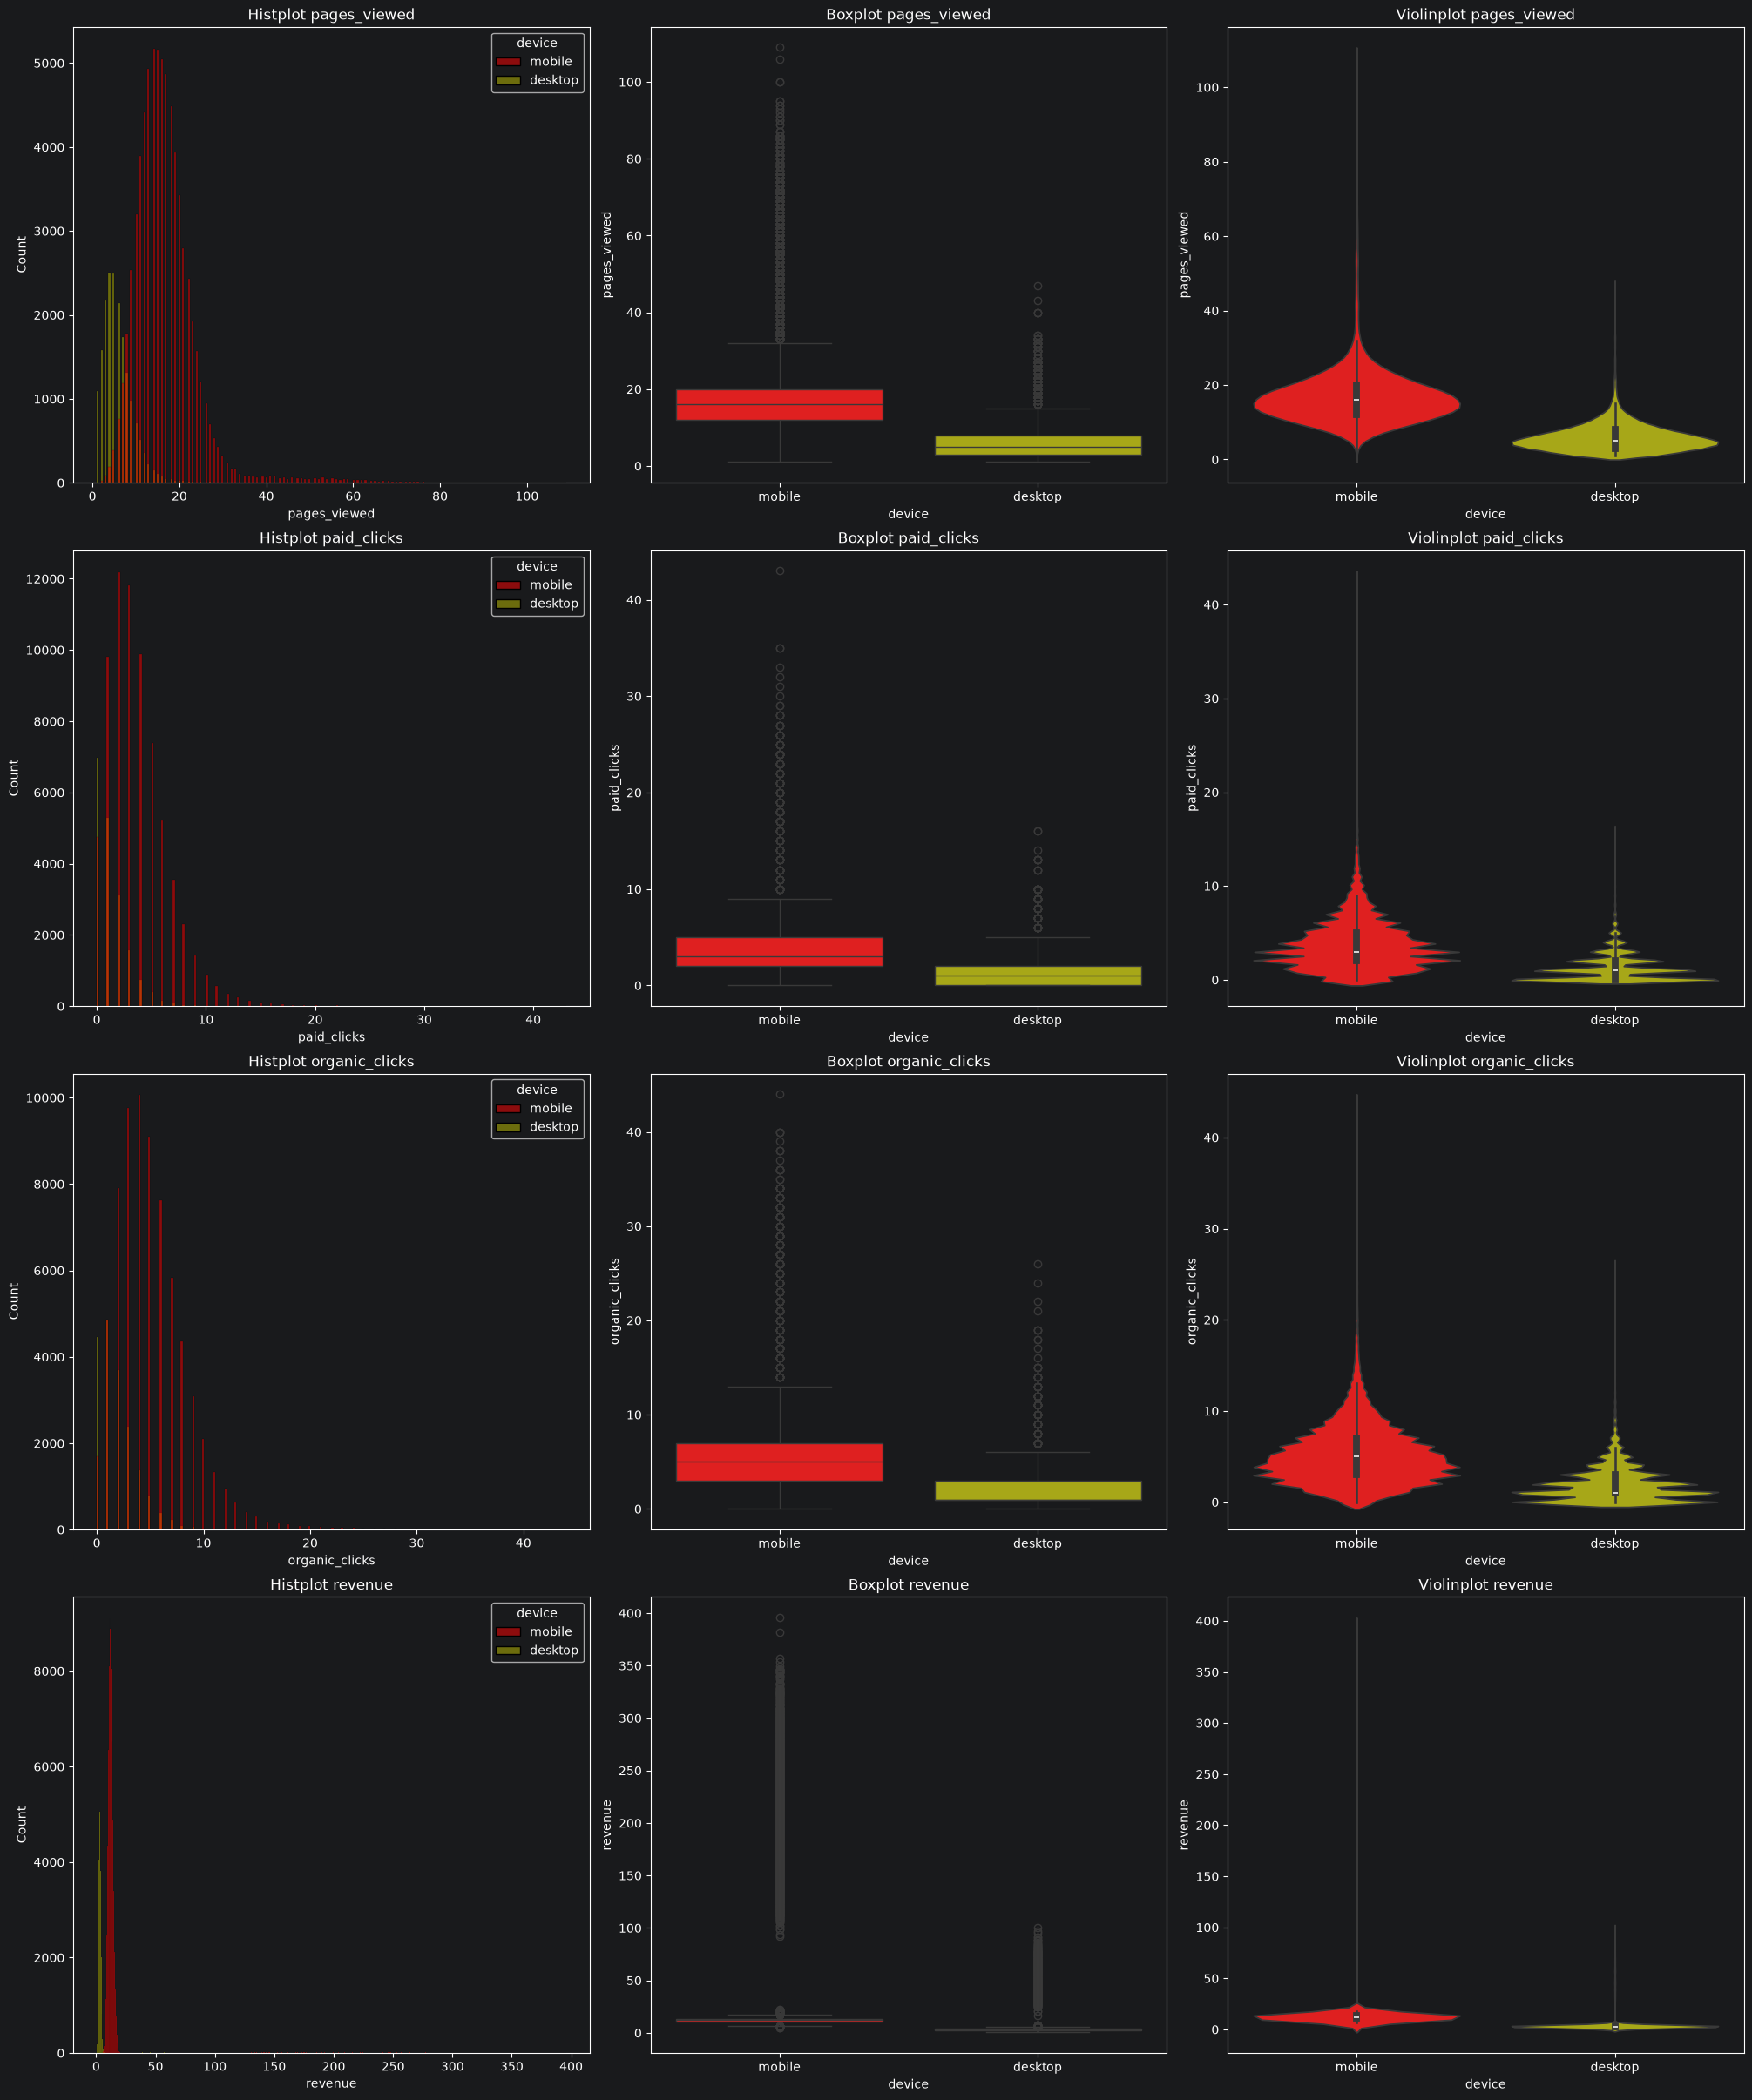

In [19]:
build_graphics(user_activity, 'pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue', hue='device')

Построенные графики подтверждают ранее сделанные математические выводы. В дополнение можно отметить, что:
- графики Violinplot для `pages_viewed` наглядно показывают разницу в поведении пользователей. Мобильное распределение имеет классическую форму с центром в районе 14–16 страниц. А десктопное распределение максимально прижато к нулю и имеет более плоскую форму, что подтверждает: пользователи ПК просматривают значительно меньше страниц;
- на графиках Boxplot для кликов и выручки видны большие вертикальные шлейфы из точек над «усами» ящика (пользователи-выбросы);
- выбросы на мобильных устройствах намного мощнее десктопных (например, в revenue десктопный шлейф точек заканчивается в районе 100, в то время как мобильный тянется до отметки 400);
- график Histplot для выручки показал экстремальную правостороннюю асимметрию. Абсолютное большинство транзакций сосредоточено в узком промежутке (примерно до 25), а единичные крупные чеки очень сильно растянулись по оси X вплоть до 400.


### Очистка выбросов

Согласно проведенному ранее анализу было установлено, что поведение пользователей и их показатели в разрезе платформ кардинально отличаются. Поэтому очистку вбросов необходимо провести отдельно для каждой платформы и затем объединить их в единый очищенный датасет.

In [20]:
# Функция для очистки аномальных значений в данных
def remove_outliners(data, *args):

    cleaned_data = data.copy()

    if not args:
        return cleaned_data

    for column in args:
        Q1 = np.percentile(cleaned_data[column], 25)
        Q3 = np.percentile(cleaned_data[column], 75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        cleaned_data = cleaned_data[(cleaned_data[column] >= lower_bound) & (cleaned_data[column] <= upper_bound)]

    return cleaned_data

In [21]:
# Удалим выбросы отдельно для пользователей desktop и mobile. Затем объединим их в общий очищенный датасет
cleaned_user_activity_desktop = remove_outliners(user_activity_desktop, 'revenue')
cleaned_user_activity_mobile = remove_outliners(user_activity_mobile, 'revenue')
cleaned_user_activity = pd.concat([cleaned_user_activity_desktop, cleaned_user_activity_mobile], ignore_index=True)

In [22]:
percent_removed = (len(user_activity) - len(cleaned_user_activity)) / len(user_activity) * 100
print('Процент удаленных данных составляет {:.2F}%'.format(percent_removed))

Процент удаленных данных составляет 3.60%


In [23]:
get_info(cleaned_user_activity)

------ Первые 5 строк ------


,date,user_id,device,pages_viewed,paid_clicks,organic_clicks,revenue
0,2026-01-01,4,desktop,6,0,4,5.13
1,2026-01-01,6,desktop,6,2,0,3.89
2,2026-01-01,15,desktop,3,1,4,2.61
3,2026-01-01,26,desktop,1,6,1,1.69
4,2026-01-01,29,desktop,6,0,4,3.72



------ Типы данных ------
<class 'pandas.DataFrame'>
RangeIndex: 86138 entries, 0 to 86137
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   date            86138 non-null  datetime64[ns]
 1   user_id         86138 non-null  int64         
 2   device          86138 non-null  str           
 3   pages_viewed    86138 non-null  int64         
 4   paid_clicks     86138 non-null  int64         
 5   organic_clicks  86138 non-null  int64         
 6   revenue         86138 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(4), str(1)
memory usage: 4.6 MB

------ Уникальные значения в файле ------


date                56
user_id           3000
device               2
pages_viewed        96
paid_clicks         36
organic_clicks      42
revenue           1586
dtype: int64


------ Пропуски в файле ------


date              0
user_id           0
device            0
pages_viewed      0
paid_clicks       0
organic_clicks    0
revenue           0
dtype: int64


------ Дубликаты в файле ------


np.int64(0)

**Выводы:**
- процент удаленных данных составляет 3.60% (в рамках приемлемого диапазона 1-5%);
- количество уникальных пользователей и дней не изменилось.

## Исследовательский анализ данных (после очистки выбросов)

### Изучение медианы, моды, средних значений и стандартных отклонений

In [24]:
cleaned_user_activity[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].describe().T

,count,mean,std,min,25%,50%,75%,max
pages_viewed,86138.00,14.71,8.55,1.00,9.00,14.00,19.00,109.00
paid_clicks,86138.00,3.24,2.80,0.00,1.00,3.00,5.00,43.00
organic_clicks,86138.00,4.54,3.48,0.00,2.00,4.00,6.00,44.00
revenue,86138.00,10.14,4.06,0.52,9.04,11.27,12.88,17.65


In [25]:
cleaned_user_activity[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].mode().T[0]

pages_viewed     14.00
paid_clicks       2.00
organic_clicks    3.00
revenue          11.57
Name: 0, dtype: float64

**Выводы:**

- в результате фильтрации методом IQR максимальное значение `revenue` снизилось с 395.72 до 17.65, что позволило устранить экстремальную правостороннюю асимметрию и снизить стандартное отклонение до 4.06;
- очистка затронула только финансовые выбросы, полностью сохранив распределение метрик активности пользователей (`pages_viewed`, `paid_clicks`, `organic_clicks`).

In [26]:
cleaned_user_activity_desktop[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].describe().T

,count,mean,std,min,25%,50%,75%,max
pages_viewed,17704.00,5.89,3.68,1.00,3.00,5.00,8.00,47.00
paid_clicks,17704.00,1.27,1.47,0.00,0.00,1.00,2.00,16.00
organic_clicks,17704.00,1.91,1.91,0.00,1.00,1.00,3.00,26.00
revenue,17704.00,2.97,0.89,0.52,2.32,2.90,3.55,5.59


In [27]:
cleaned_user_activity_desktop[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].mode().T[0]

pages_viewed     4.00
paid_clicks      0.00
organic_clicks   1.00
revenue          2.55
Name: 0, dtype: float64

In [28]:
cleaned_user_activity_mobile[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].describe().T

,count,mean,std,min,25%,50%,75%,max
pages_viewed,68434.00,16.99,7.95,1.00,12.00,16.00,20.00,109.00
paid_clicks,68434.00,3.75,2.83,0.00,2.00,3.00,5.00,43.00
organic_clicks,68434.00,5.21,3.48,0.00,3.00,5.00,7.00,44.00
revenue,68434.00,12.00,1.94,6.50,10.62,11.90,13.28,17.65


In [29]:
cleaned_user_activity_mobile[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].mode().T[0]

pages_viewed     14.00
paid_clicks       2.00
organic_clicks    4.00
revenue          11.57
Name: 0, dtype: float64

In [30]:
cleaned_user_activity.groupby(['device'])[['pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue']].sum().reset_index()

,device,pages_viewed,paid_clicks,organic_clicks,revenue
0,desktop,104205,22404,33854,52497.66
1,mobile,1162632,256603,356868,821062.87


**Выводы:**

- благодаря фильтрации данные по выручке стали более однородными:
    - для десктопного сегмента - максимум снизился с 99.97 до 5.59, средний чек - с 4.40 до 2.97, а стандартное отклонение - с 8.61 до 0.89;
    - на мобильных устройствах - максимум снизился с 395.72 до 17.65, средний чек - с 17.85 до 12.00, а стандартное отклонение - с 34.89 до 1.94.
- распределение метрик активности пользователей (`pages_viewed`, `paid_clicks`, `organic_clicks`) в разрезе платформ сохранилось.

### Построение графиков распределения признаков, boxplot и violinplot для пользователей в разрезе платформ

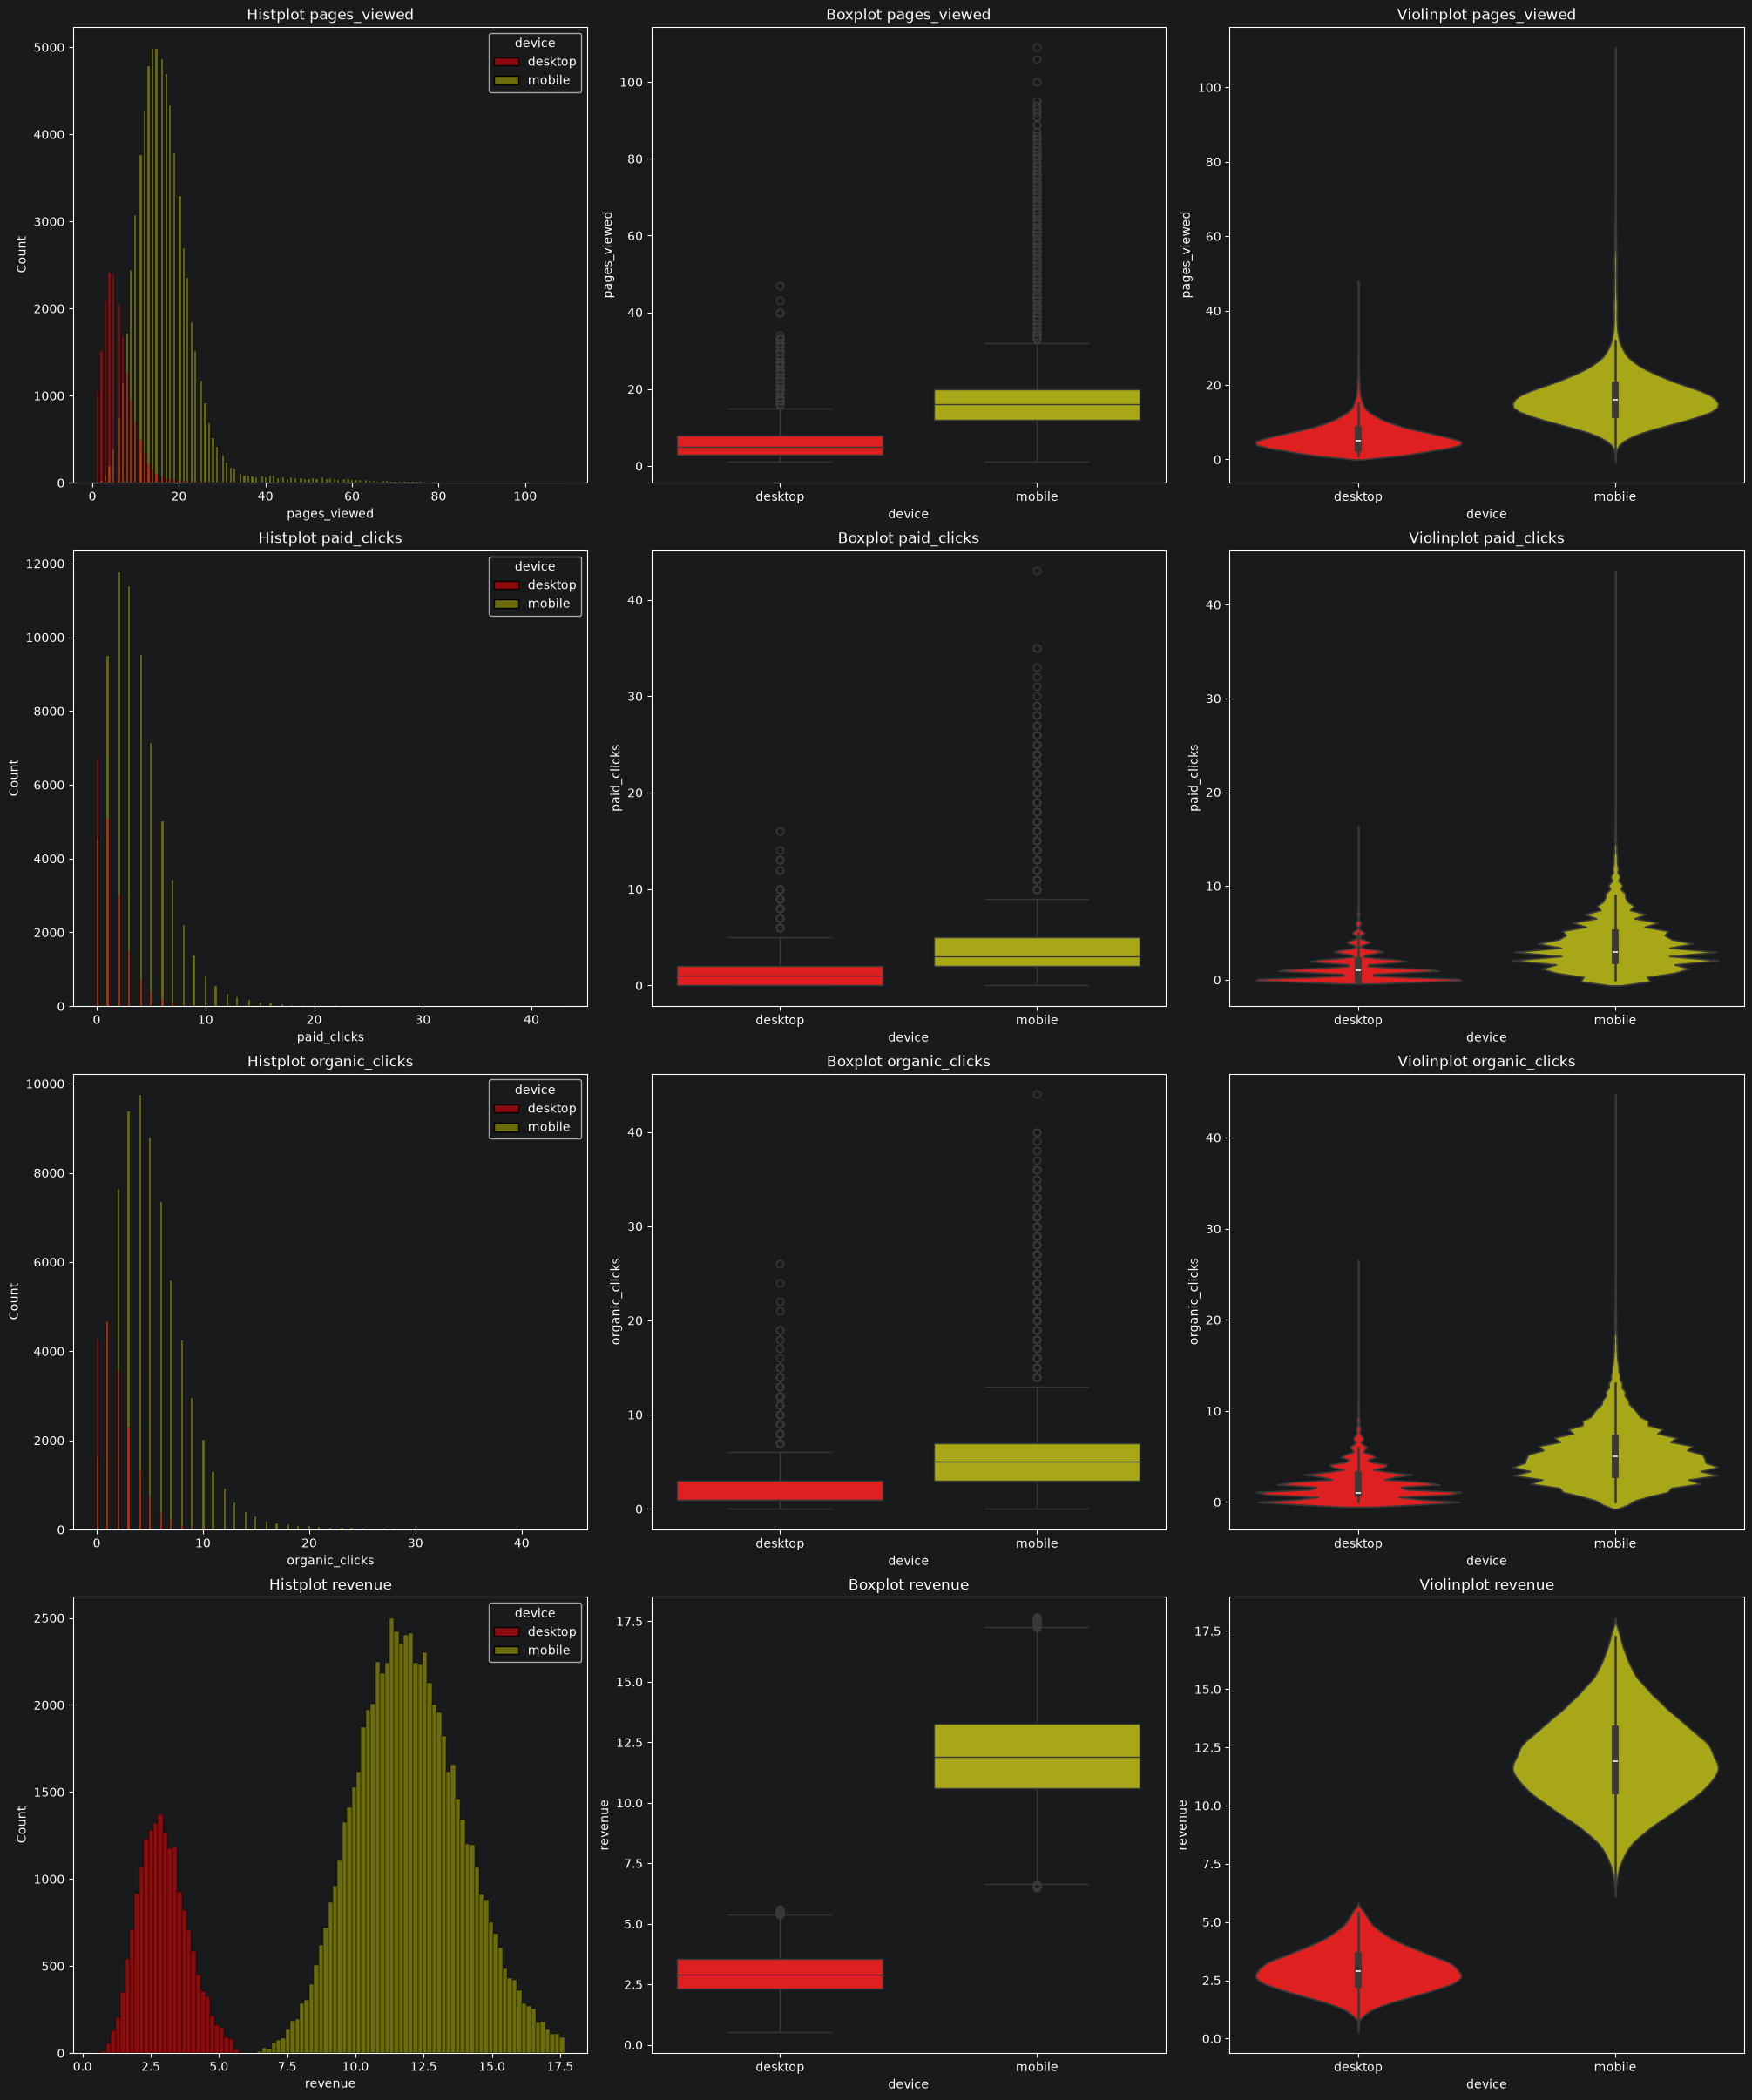

In [31]:
build_graphics(cleaned_user_activity, 'pages_viewed', 'paid_clicks', 'organic_clicks', 'revenue', hue='device')

**Выводы:**

Графики наглядно подтверждает успешность проведенной предобработки:
- на графиках Histplot и Violinplot для `revenue` вместо сжатых распределений сформировались два четких, симметричных колокола, близких к нормальному распределению;
- графики Boxplot по выручке полностью очистились от больших шлейфов аномальных выбросов, данные в разрезе платформ стали однородными;
- графики для `pages_viewed`, `paid_clicks` и `organic_clicks` сохранили свой первоначальный вид, т.е. очистка `revenue` не исказила исходную структуру поведенческой активности пользователей.


### Метрики конверсии: из просмотров в платные и органические клики

In [32]:
# Добавление метрик конверсии (Paid CTR и Organic CTR)
cleaned_user_activity['paid_ctr'] = cleaned_user_activity['paid_clicks'] / cleaned_user_activity['pages_viewed']
cleaned_user_activity['organic_ctr'] = cleaned_user_activity['organic_clicks'] / cleaned_user_activity['pages_viewed']
cleaned_user_activity.head()

,date,user_id,device,pages_viewed,paid_clicks,organic_clicks,revenue,paid_ctr,organic_ctr
0,2026-01-01,4,desktop,6,0,4,5.13,0.00,0.67
1,2026-01-01,6,desktop,6,2,0,3.89,0.33,0.00
2,2026-01-01,15,desktop,3,1,4,2.61,0.33,1.33
3,2026-01-01,26,desktop,1,6,1,1.69,6.00,1.00
4,2026-01-01,29,desktop,6,0,4,3.72,0.00,0.67


Учитывая существенную разницу в поведении пользователей между платформами, анализ взаимосвязей между метриками проведем в разрезе Mobile и Desktop во избежание смещения оценок.

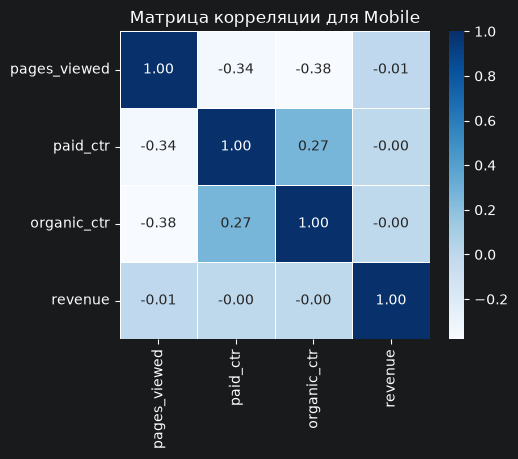

In [33]:
needed_columns = ['pages_viewed', 'paid_ctr', 'organic_ctr', 'revenue']
plt.figure(figsize=(5, 4))
sns.heatmap(data=cleaned_user_activity[cleaned_user_activity['device'] == 'mobile'][needed_columns].corr(), annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Матрица корреляции для Mobile')
plt.show()

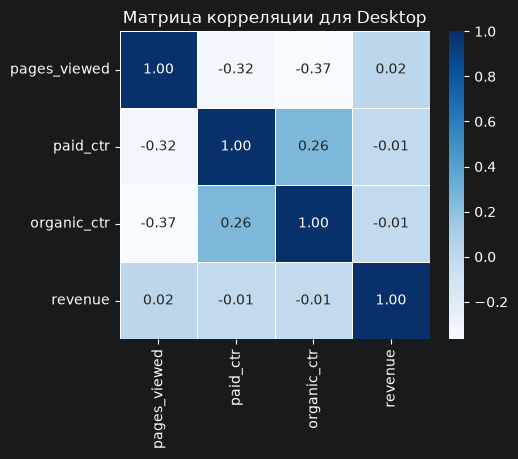

In [34]:
plt.figure(figsize=(5, 4))
sns.heatmap(data=cleaned_user_activity[cleaned_user_activity['device'] == 'desktop'][needed_columns].corr(), annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Матрица корреляции для Desktop')
plt.show()

**Выводы:**
- размер выручки `revenue` не зависит линейно от количества просмотренных страниц или кликов по элементам;
- между количеством просмотров `pages_viewed` и кликабельностью наблюдается отрицательная корреляция: с `paid_ctr` она составляет -0.34 и -0.32 для Mobile и Desktop соответственно, а с `organic_ctr` равна -0.38 и -0.37. Чем больше страниц пользователь просматривает, тем меньше кликает по элементам;
- корреляция между `paid_clicks` и `organic_clicks` очень слабая (0.27 и 0.26 для Mobile и Desktop соответственно). Пользователи взаимодействуют и с платными, и с органическими элементами одновременно, но независимо друг от друга.

## Дизайн теста

**Цель теста:** Увеличение конверсии по платным и органическим элементам, что приведет к росту выручки.


**Выбор аудитории:** Учитывая ограниченное количество пользователей (3000), в тесте будут участвовать все. Тестирование целесообразнее разделить на два отдельных сегмента - Mobile и Desktop, т.к. поведение пользователей в зависимости от платформы кардинально отличаются. Сегменты случайно разделим на тестовую группу и контрольную (50/50) для каждой платформы.

**Различия для групп А и В:** Расположение элементов в ленте:
- группа А (контрольная): 1 "органический" элемент наверху + 4 "платных" элемента внизу;
- группы B (тестовая): 4 "платных" элемент наверху + 1 "органический" элемент внизу.

**Гипотезы:** Изменения порядка расположения "органических" и "платных" элементов в ленте списка объявлений на платформе Marketpele Feed изменит конверсию в клики по платным и органическим элементам.

- Сегмент MOBILE:

	- Гипотеза 1 (Платные):

		- Н0: Изменение расположения элементов не имеет эффекта и не меняет конверсию в клики по платным элементам, различия между контрольной и тестовой группами случайны и статистически не значимы;
		- Н1: Изменение расположения элементов имеет эффект, конверсия в клики по платным элементам в тестовой группе значимо отличается от контрольной.

	- Гипотеза 2 (Органические):

		- Н0: Изменение расположения элементов не имеет эффекта и не меняет конверсию в клики по органическим элементам, различия между контрольной и тестовой группами случайны и статистически не значимы;
		- Н1: Изменение расположения элементов имеет эффект, конверсия в клики по органическим элементам в тестовой группе значимо отличается от контрольной.


- Сегмент DESKTOP:

	- Гипотеза 3 (Платные):

		- Н0: Изменение расположения элементов не имеет эффекта и не меняет конверсию в клики по платным элементам, различия между контрольной и тестовой группами случайны и статистически не значимы;
		- Н1: Изменение расположения элементов имеет эффект, конверсия в клики по платным элементам в тестовой группе значимо отличается от контрольной.

	- Гипотеза 4 (Органические):

		- Н0: Изменение расположения элементов не имеет эффекта и не меняет конверсию в клики по органическим элементам, различия между контрольной и тестовой группами случайны и статистически не значимы;
		- Н1: Изменение расположения элементов имеет эффект, конверсия в клики по органическим элементам в тестовой группе значимо отличается от контрольной.


**Ключевые показатели:** Показатели будут рассчитываться на уровне пользователей.
- целевые метрики - `paid_ctr`, `organic_ctr`;
- дополнительная метрика - `pages_viewed`;
- страховочная метрика - `revenue`.

**Уровень значимости:** 0.025 (0.05 / 2 - с поправкой Бонферрони, т.к. в каждом сегменте проверяем две гипотезы, две продуктовые метрики).

**Мощность теста:** 80%

### Расчет объема выборки и MDE

Для выбора оптимальной длительности теста посчитаем MDE для нескольких вариантов: 2, 3 и 4 недели.

Учитывая, что трафик ограничен закрытой когортой в 3000 пользователей, классические онлайн-калькуляторы не применялись.

Фактический размер контрольной и тестовой групп для каждой длительности определяется на основе исторических данных как половина от числа уникальных пользователей, посетивших сайт за соответствующий период.

Ввиду существенных различий в поведении пользователей и объемах трафика все расчеты MDE проводятся отдельно для сегментов Mobile и Desktop. Для обеспечения независимости данных агрегируем данные на уровне user_id.

In [35]:
# Рассчитаем размеры групп за i недель на основе исторических данных
def sample_size(data, weeks):

    df_n_weeks = data[data["date"] <= (data["date"].min() + pd.Timedelta(weeks=weeks))]

    # Считаем уникальных и делим на 2 группы
    n_mobile = (df_n_weeks[df_n_weeks["device"] == "mobile"]["user_id"].nunique() / 2)
    n_desktop = (df_n_weeks[df_n_weeks["device"] == "desktop"]["user_id"].nunique() / 2)

    print(f"Размер группы за {weeks} недели: Mobile = {int(n_mobile)}, Desktop = {int(n_desktop)}")

sample_size(cleaned_user_activity, 2)
sample_size(cleaned_user_activity, 3)
sample_size(cleaned_user_activity, 4)

Размер группы за 2 недели: Mobile = 1157, Desktop = 303
Размер группы за 3 недели: Mobile = 1175, Desktop = 307
Размер группы за 4 недели: Mobile = 1185, Desktop = 310


In [36]:
# Агрегируем данные на уровень пользователей
user_level_df = cleaned_user_activity.groupby(['user_id', 'device']).agg(
    total_pages=('pages_viewed', 'sum'),
    total_paid_clicks=('paid_clicks', 'sum'),
    total_organic_clicks=('organic_clicks', 'sum'),
    total_revenue=('revenue', 'sum')
).reset_index()

# Считаем метрики CTR для каждого пользователя
user_level_df['user_paid_ctr'] = user_level_df['total_paid_clicks'] / user_level_df['total_pages']
user_level_df['user_organic_ctr'] = user_level_df['total_organic_clicks'] / user_level_df['total_pages']

In [37]:
user_level_df.head(3)

,user_id,device,total_pages,total_paid_clicks,total_organic_clicks,total_revenue,user_paid_ctr,user_organic_ctr
0,0,mobile,770,169,194,635.03,0.22,0.25
1,1,mobile,686,157,124,448.76,0.23,0.18
2,2,mobile,178,31,108,108.38,0.17,0.61


In [38]:
# Расчет квантилей
alpha = 0.05
k_metrics = 2  # поправка Бонферрони под 2 метрики
power_target = 0.80

# Расчет альфа с учетом поправки Бонферрони
alpha_bonf = alpha / k_metrics

# Квантиль для уровня значимости (двусторонний тест)
z_alpha = stats.norm.ppf(1 - alpha_bonf / 2)

# Квантиль для мощности теста (односторонний)
z_beta = stats.norm.ppf(power_target)

# Сумма квантилей
z_sum = z_alpha + z_beta

In [39]:
# Подготовим данные по объемам выборок для расчета MDE
duration_designs = {
    "2 недели": {"mobile": 1157, "desktop": 303},
    "3 недели": {"mobile": 1175, "desktop": 307},
    "4 недели": {"mobile": 1185, "desktop": 310},
}

MDE_table = []

# Рассчитаем MDE
for device in ["mobile", "desktop"]:
    for metric in ["user_paid_ctr", "user_organic_ctr"]:
        df_device = user_level_df[user_level_df["device"] == device]

        mu = df_device[metric].mean()
        sigma = df_device[metric].std()

        print(
            f"---- Расчет MDE для {device.upper()} - метрика {metric.upper()} ----"
        )
        print(f"Среднее: {mu:.4f}, отклонение: {sigma:.4f}")

        for duration, n_dict in duration_designs.items():
            n = n_dict[device]

            # Расчет абсолютного MDE
            mde_absolute = z_sum * np.sqrt((2 * (sigma**2)) / n)

            # Расчет относительного MDE
            mde_relative = (mde_absolute / mu) * 100

            print(
                f"Срок {duration} (n={n} чел) - MDE = {mde_relative:.2f}%"
            )
        print("-" * 55 + "\n")

---- Расчет MDE для MOBILE - метрика USER_PAID_CTR ----
Среднее: 0.2303, отклонение: 0.1222
Срок 2 недели (n=1157 чел) - MDE = 6.80%
Срок 3 недели (n=1175 чел) - MDE = 6.75%
Срок 4 недели (n=1185 чел) - MDE = 6.72%
-------------------------------------------------------

---- Расчет MDE для MOBILE - метрика USER_ORGANIC_CTR ----
Среднее: 0.3259, отклонение: 0.1563
Срок 2 недели (n=1157 чел) - MDE = 6.15%
Срок 3 недели (n=1175 чел) - MDE = 6.10%
Срок 4 недели (n=1185 чел) - MDE = 6.08%
-------------------------------------------------------

---- Расчет MDE для DESKTOP - метрика USER_PAID_CTR ----
Среднее: 0.2393, отклонение: 0.2240
Срок 2 недели (n=303 чел) - MDE = 23.45%
Срок 3 недели (n=307 чел) - MDE = 23.30%
Срок 4 недели (n=310 чел) - MDE = 23.19%
-------------------------------------------------------

---- Расчет MDE для DESKTOP - метрика USER_ORGANIC_CTR ----
Среднее: 0.3767, отклонение: 0.2934
Срок 2 недели (n=303 чел) - MDE = 19.51%
Срок 3 недели (n=307 чел) - MDE = 19.38%
Ср

Полученные результаты MDE показывают существенные различия в чувствительности теста между платформами:
- Mobile (гипотезы 1 и 2): диапазон MDE составляет ~6.08%–6.80%. Данный порог является вполне реалистичным и достижимым для бизнеса;
 - Desktop (гипотезы 3 и 4): диапазон MDE составляет ~19.29–23.45%, что очень высоко из-за малого объема выборки. Проверка гипотез неэффективна, так как подобные приросты CTR не встречаются в реальном бизнесе.

### Симуляция А/А и А/Б-тестов

Для валидации рассчитанных параметров проведем серию симуляций А/А и А/Б-тестов (100 000 итераций) на исторических данных, чтобы проверить контроль ошибок первого рода (FPR) и оценить фактическую статистическую мощность критерия (Power).

In [40]:
# Функция для проведения симуляции А/А и А/Б-тестов
def run_aa_ab_simulation(user_df, device, metric, n_group, mde_relative, alpha=0.025, simulations=10000):
    # Фильтруем данные под платформу
    df_filtered = user_df[user_df['device'] == device][metric].values

    mean_val = np.mean(df_filtered)
    absolute_effect = mean_val * (mde_relative / 100)

    aa_p_values = []
    ab_p_values = []

    for i in range(simulations):
        # Генерируем уникальные случайные индексы сразу для обеих групп
        indices = np.random.permutation(len(df_filtered))

        n_group_actual = min(n_group, len(df_filtered) // 2)

        idx_A1 = indices[:n_group_actual]
        idx_A2 = indices[n_group_actual : 2 * n_group_actual]

        # Формируем группы А1 и А2
        group_A1 = df_filtered[idx_A1]
        group_A2 = df_filtered[idx_A2]

        # Формируем группу В с эффектом MDE
        group_B = group_A2 + absolute_effect

        # Считаем p-value для обоих случаев через t-test
        p_val_aa = stats.ttest_ind(group_A1, group_A2, equal_var=True).pvalue
        p_val_ab = stats.ttest_ind(group_A1, group_B, equal_var=True).pvalue

        aa_p_values.append(p_val_aa)
        ab_p_values.append(p_val_ab)

    # FPR — доля ложноположительных результатов в АА-тесте
    fpr = np.mean(np.array(aa_p_values) < alpha)
    # Мощность — доля успешно зафиксированных эффектов в АБ-тесте
    power = np.mean(np.array(ab_p_values) < alpha)

    print(f"---- Результаты симуляции для {device.upper()} - метрика {metric.upper()} ----")
    print(f"n={n_group} чел")
    print(f"Ложноположительные срабатывания (FPR): {fpr*100:.2f}% (Ожидалось: {alpha*100}%)")
    print(f"Мощность теста (Power): {power*100:.2f}% (Ожидалось: >= 80%)")
    print("-" * 65 + "\n")

In [41]:
# Запустим симуляцию для 2 недель с рассчитанной выборкой и MDE
run_aa_ab_simulation(user_level_df, 'mobile', 'user_paid_ctr', n_group=1157, mde_relative=6.80)
run_aa_ab_simulation(user_level_df, 'mobile', 'user_organic_ctr', n_group=1157, mde_relative=6.15)
run_aa_ab_simulation(user_level_df, 'desktop', 'user_paid_ctr', n_group=303, mde_relative=23.45)
run_aa_ab_simulation(user_level_df, 'desktop', 'user_organic_ctr', n_group=303, mde_relative=19.51)

---- Результаты симуляции для MOBILE - метрика USER_PAID_CTR ----
n=1157 чел
Ложноположительные срабатывания (FPR): 2.51% (Ожидалось: 2.5%)
Мощность теста (Power): 80.23% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для MOBILE - метрика USER_ORGANIC_CTR ----
n=1157 чел
Ложноположительные срабатывания (FPR): 2.32% (Ожидалось: 2.5%)
Мощность теста (Power): 79.43% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для DESKTOP - метрика USER_PAID_CTR ----
n=303 чел
Ложноположительные срабатывания (FPR): 2.35% (Ожидалось: 2.5%)
Мощность теста (Power): 80.83% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для DESKTOP - метрика USER_ORGANIC_CTR ----
n=303 чел
Ложноположительные срабатывания (FPR): 2.39% (Ожидалось: 2.5%)
Мощность теста (Power): 79.68% (Ожидалось: >= 80%)
-----------------------------

In [42]:
# Запустим симуляцию для 3 недель с рассчитанной выборкой и MDE
run_aa_ab_simulation(user_level_df, 'mobile', 'user_paid_ctr', n_group=1175, mde_relative=6.75)
run_aa_ab_simulation(user_level_df, 'mobile', 'user_organic_ctr', n_group=1175, mde_relative=6.10)
run_aa_ab_simulation(user_level_df, 'desktop', 'user_paid_ctr', n_group=307, mde_relative=23.30)
run_aa_ab_simulation(user_level_df, 'desktop', 'user_organic_ctr', n_group=307, mde_relative=19.38)

---- Результаты симуляции для MOBILE - метрика USER_PAID_CTR ----
n=1175 чел
Ложноположительные срабатывания (FPR): 2.25% (Ожидалось: 2.5%)
Мощность теста (Power): 80.15% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для MOBILE - метрика USER_ORGANIC_CTR ----
n=1175 чел
Ложноположительные срабатывания (FPR): 2.36% (Ожидалось: 2.5%)
Мощность теста (Power): 80.02% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для DESKTOP - метрика USER_PAID_CTR ----
n=307 чел
Ложноположительные срабатывания (FPR): 2.60% (Ожидалось: 2.5%)
Мощность теста (Power): 79.59% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для DESKTOP - метрика USER_ORGANIC_CTR ----
n=307 чел
Ложноположительные срабатывания (FPR): 2.51% (Ожидалось: 2.5%)
Мощность теста (Power): 79.82% (Ожидалось: >= 80%)
-----------------------------

In [43]:
# Запустим симуляцию для 4 недель с рассчитанной выборкой и MDE
run_aa_ab_simulation(user_level_df, 'mobile', 'user_paid_ctr', n_group=1185, mde_relative=6.72)
run_aa_ab_simulation(user_level_df, 'mobile', 'user_organic_ctr', n_group=1185, mde_relative=6.08)
run_aa_ab_simulation(user_level_df, 'desktop', 'user_paid_ctr', n_group=310, mde_relative=23.19)
run_aa_ab_simulation(user_level_df, 'desktop', 'user_organic_ctr', n_group=310, mde_relative=19.29)

---- Результаты симуляции для MOBILE - метрика USER_PAID_CTR ----
n=1185 чел
Ложноположительные срабатывания (FPR): 2.59% (Ожидалось: 2.5%)
Мощность теста (Power): 80.38% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для MOBILE - метрика USER_ORGANIC_CTR ----
n=1185 чел
Ложноположительные срабатывания (FPR): 2.59% (Ожидалось: 2.5%)
Мощность теста (Power): 80.40% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для DESKTOP - метрика USER_PAID_CTR ----
n=310 чел
Ложноположительные срабатывания (FPR): 2.29% (Ожидалось: 2.5%)
Мощность теста (Power): 79.99% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для DESKTOP - метрика USER_ORGANIC_CTR ----
n=310 чел
Ложноположительные срабатывания (FPR): 2.70% (Ожидалось: 2.5%)
Мощность теста (Power): 79.62% (Ожидалось: >= 80%)
-----------------------------

Результаты симуляции АА/АБ-тестов:
- Контроль ошибок (FPR): Уровень ложных срабатываний в АА-симуляциях удерживается в диапазоне ~2–3%, что подтверждает корректность сплитования групп и доказывает, что поправка Бонферрони защищает эксперимент от случайных ложноположительных выводов;
- Мощность тестов (Power): Мощность критерия практически достигает целевого ориентира в 80% по всем продуктовым метрикам.

### Применение метода CUPED

Несмотря на выполнение требований по мощности, в текущий дизайн заложены высокие и труднодостижимые на практике пороги MDE. Чтобы повысить чувствительность эксперимента (сделать критерий более точным) применим метод CUPED.

Для этого данные по активности пользователей разделим на два независимых временных отрезка: исторические данные за январь (в качестве ковариаты) и экспериментальные данные за февраль (тестовый период).

In [44]:
# Разделим данные на два периода: январь - исторические, февраль - тестовые
# Январь - исторические
df_history_user = (
    cleaned_user_activity[cleaned_user_activity["date"] <= "2026-01-31"]
    .groupby(["user_id", "device"])
    .agg(
        hist_organic_clicks=("organic_clicks", "sum"),
        hist_paid_clicks=("paid_clicks", "sum"),
        hist_pages=("pages_viewed", "sum"),
    )
    .reset_index()
)

# Считаем исторический CTR для каждого пользователя
df_history_user["user_organic_ctr_history"] = (df_history_user["hist_organic_clicks"] / df_history_user["hist_pages"])
df_history_user["user_paid_ctr_history"] = (df_history_user["hist_paid_clicks"] / df_history_user["hist_pages"])

# Февраль - тестовые
df_test_user = (
    cleaned_user_activity[cleaned_user_activity["date"] > "2026-01-31"]
    .groupby("user_id")
    .agg(
        test_organic_clicks=("organic_clicks", "sum"),
        test_paid_clicks=("paid_clicks", "sum"),
        test_pages=("pages_viewed", "sum"),
    )
    .reset_index()
)

# Считаем тестовый CTR для каждого пользователя
df_test_user["user_organic_ctr_test"] = (df_test_user["test_organic_clicks"] / df_test_user["test_pages"])
df_test_user["user_paid_ctr_test"] = (df_test_user["test_paid_clicks"] / df_test_user["test_pages"])

# Объединим все в одну таблицу, оставим только тех пользователей, которые заходили и в январе, и в феврале
agg_data = pd.merge(
    df_history_user[["user_id", "device", "user_organic_ctr_history", "user_paid_ctr_history"]],
    df_test_user[["user_id", "user_organic_ctr_test", "user_paid_ctr_test"]],
    on="user_id",
    how="inner",
)

In [45]:
# Функция для применения метода CUPED
def apply_cuped_to_df(data, metric_test, metric_history):
    df_cuped = data.copy()
    new_column_name = f"{metric_test}_cuped"
    df_cuped[new_column_name] = np.nan

    # Расчет по устройствам
    for device in ["mobile", "desktop"]:
        # Исторические и тестовые данные для конкретной платформы
        mask = df_cuped["device"] == device
        x_test = df_cuped.loc[mask, metric_test].values
        x_hist = df_cuped.loc[mask, metric_history].values

        # Считаем ковариацию и дисперсию истории
        cov_matrix = np.cov(x_test, x_hist)
        covariance = cov_matrix[0, 1]
        variance_hist = np.var(x_hist)

        # Вычисляем коэффициент theta
        theta = covariance / variance_hist

        # Находим среднее историческое значение платформы
        mean_hist = np.mean(x_hist)

        # Применяем CUPED
        df_cuped.loc[mask, new_column_name] = x_test - theta * (x_hist - mean_hist)

    return df_cuped

In [46]:
# Применяем CUPED к платному и органическому CTR
cuped_data = agg_data.copy()
cuped_data = apply_cuped_to_df(cuped_data, 'user_paid_ctr_test', 'user_paid_ctr_history')
cuped_data = apply_cuped_to_df(cuped_data, 'user_organic_ctr_test', 'user_organic_ctr_history')

In [47]:
# Проверим измененные данные
cuped_data.head()

,user_id,device,user_organic_ctr_history,user_paid_ctr_history,user_organic_ctr_test,user_paid_ctr_test,user_paid_ctr_test_cuped,user_organic_ctr_test_cuped
0,0,mobile,0.25,0.21,0.25,0.24,0.26,0.31
1,1,mobile,0.15,0.24,0.22,0.21,0.21,0.36
2,2,mobile,0.61,0.17,0.61,0.18,0.23,0.39
3,3,mobile,0.26,0.01,0.33,0.08,0.26,0.39
4,4,desktop,0.64,0.22,0.75,0.21,0.23,0.50


### Расчет MDE с применение метода CUPED

In [48]:
# Рассчитаем MDE с применением метода CUPED
for device in ["mobile", "desktop"]:
    for metric in ["user_paid_ctr", "user_organic_ctr"]:
        metric_test = f"{metric}_test"
        metric_history = f"{metric}_history"

        df_device = cuped_data[cuped_data["device"] == device]

        mu = df_device[metric_test].mean()
        sigma_test = df_device[metric_test].std()

        x_test = df_device[metric_test].values
        x_hist = df_device[metric_history].values

        # Считаем ковариацию и дисперсию истории
        cov_matrix = np.cov(x_test, x_hist)
        covariance = cov_matrix[0, 1]
        variance_hist = np.var(x_hist, ddof=1)

        # Вычисляем коэффициент Theta
        theta = covariance / variance_hist

        # Находим CUPED дисперсию
        variance_test = sigma_test ** 2
        variance_cuped = variance_test - theta * covariance

        # Находим CUPED стандартное отклонению
        sigma_cuped = np.sqrt(variance_cuped)

        print(f"--- Расчет CUPED MDE для {device.upper()} - метрика {metric.upper()} ---")
        print(f"Среднее: {mu:.4f}, отклонение: {sigma_test:.4f}, Theta: {theta:.4f}, CUPED отклонение: {sigma_cuped:.4f}")

        for duration, n_dict in duration_designs.items():
            n = n_dict[device]

            # Считаем CUPED MDE
            mde_absolute = z_sum * np.sqrt((2 * (sigma_cuped**2)) / n)
            mde_relative = (mde_absolute / mu) * 100

            print(f"Срок {duration} (n={n} чел) - MDE = {mde_relative:.2f}%")

        print("-" * 55 + "\n")

--- Расчет CUPED MDE для MOBILE - метрика USER_PAID_CTR ---
Среднее: 0.2336, отклонение: 0.1353, Theta: 0.8265, CUPED отклонение: 0.0836
Срок 2 недели (n=1157 чел) - MDE = 4.59%
Срок 3 недели (n=1175 чел) - MDE = 4.55%
Срок 4 недели (n=1185 чел) - MDE = 4.53%
-------------------------------------------------------

--- Расчет CUPED MDE для MOBILE - метрика USER_ORGANIC_CTR ---
Среднее: 0.3317, отклонение: 0.1842, Theta: 0.7941, CUPED отклонение: 0.1277
Срок 2 недели (n=1157 чел) - MDE = 4.94%
Срок 3 недели (n=1175 чел) - MDE = 4.90%
Срок 4 недели (n=1185 чел) - MDE = 4.88%
-------------------------------------------------------

--- Расчет CUPED MDE для DESKTOP - метрика USER_PAID_CTR ---
Среднее: 0.2414, отклонение: 0.2364, Theta: 0.8218, CUPED отклонение: 0.1421
Срок 2 недели (n=303 чел) - MDE = 14.74%
Срок 3 недели (n=307 чел) - MDE = 14.65%
Срок 4 недели (n=310 чел) - MDE = 14.58%
-------------------------------------------------------

--- Расчет CUPED MDE для DESKTOP - метрика US

### Симуляция А/А и А/Б-тестов после применения метода CUPED

In [49]:
# Запустим симуляцию для 2 недель с рассчитанной выборкой и CUPED MDE
run_aa_ab_simulation(cuped_data, 'mobile', 'user_paid_ctr_test_cuped', n_group=1157, mde_relative=4.59)
run_aa_ab_simulation(cuped_data, 'mobile', 'user_organic_ctr_test_cuped', n_group=1157, mde_relative=4.94)
run_aa_ab_simulation(cuped_data, 'desktop', 'user_paid_ctr_test_cuped', n_group=303, mde_relative=14.74)
run_aa_ab_simulation(cuped_data, 'desktop', 'user_organic_ctr_test_cuped', n_group=303, mde_relative=12.51)

---- Результаты симуляции для MOBILE - метрика USER_PAID_CTR_TEST_CUPED ----
n=1157 чел
Ложноположительные срабатывания (FPR): 2.65% (Ожидалось: 2.5%)
Мощность теста (Power): 79.20% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для MOBILE - метрика USER_ORGANIC_CTR_TEST_CUPED ----
n=1157 чел
Ложноположительные срабатывания (FPR): 2.45% (Ожидалось: 2.5%)
Мощность теста (Power): 80.08% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для DESKTOP - метрика USER_PAID_CTR_TEST_CUPED ----
n=303 чел
Ложноположительные срабатывания (FPR): 2.46% (Ожидалось: 2.5%)
Мощность теста (Power): 79.94% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для DESKTOP - метрика USER_ORGANIC_CTR_TEST_CUPED ----
n=303 чел
Ложноположительные срабатывания (FPR): 2.58% (Ожидалось: 2.5%)
Мощность теста (Power): 79.46% (Ожид

In [50]:
# Запустим симуляцию для 3 недель с рассчитанной выборкой и CUPED MDE
run_aa_ab_simulation(cuped_data, 'mobile', 'user_paid_ctr_test_cuped', n_group=1175, mde_relative=4.55)
run_aa_ab_simulation(cuped_data, 'mobile', 'user_organic_ctr_test_cuped', n_group=1175, mde_relative=4.90)
run_aa_ab_simulation(cuped_data, 'desktop', 'user_paid_ctr_test_cuped', n_group=307, mde_relative=14.65)
run_aa_ab_simulation(cuped_data, 'desktop', 'user_organic_ctr_test_cuped', n_group=307, mde_relative=12.43)

---- Результаты симуляции для MOBILE - метрика USER_PAID_CTR_TEST_CUPED ----
n=1175 чел
Ложноположительные срабатывания (FPR): 2.10% (Ожидалось: 2.5%)
Мощность теста (Power): 80.14% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для MOBILE - метрика USER_ORGANIC_CTR_TEST_CUPED ----
n=1175 чел
Ложноположительные срабатывания (FPR): 2.26% (Ожидалось: 2.5%)
Мощность теста (Power): 79.28% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для DESKTOP - метрика USER_PAID_CTR_TEST_CUPED ----
n=307 чел
Ложноположительные срабатывания (FPR): 2.41% (Ожидалось: 2.5%)
Мощность теста (Power): 80.22% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для DESKTOP - метрика USER_ORGANIC_CTR_TEST_CUPED ----
n=307 чел
Ложноположительные срабатывания (FPR): 2.78% (Ожидалось: 2.5%)
Мощность теста (Power): 79.67% (Ожид

In [51]:
# Запустим симуляцию для 4 недель с рассчитанной выборкой и CUPED MDE
run_aa_ab_simulation(cuped_data, 'mobile', 'user_paid_ctr_test_cuped', n_group=1185, mde_relative=4.53)
run_aa_ab_simulation(cuped_data, 'mobile', 'user_organic_ctr_test_cuped', n_group=1185, mde_relative=4.88)
run_aa_ab_simulation(cuped_data, 'desktop', 'user_paid_ctr_test_cuped', n_group=310, mde_relative=14.58)
run_aa_ab_simulation(cuped_data, 'desktop', 'user_organic_ctr_test_cuped', n_group=310, mde_relative=12.37)

---- Результаты симуляции для MOBILE - метрика USER_PAID_CTR_TEST_CUPED ----
n=1185 чел
Ложноположительные срабатывания (FPR): 2.37% (Ожидалось: 2.5%)
Мощность теста (Power): 79.72% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для MOBILE - метрика USER_ORGANIC_CTR_TEST_CUPED ----
n=1185 чел
Ложноположительные срабатывания (FPR): 2.13% (Ожидалось: 2.5%)
Мощность теста (Power): 80.01% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для DESKTOP - метрика USER_PAID_CTR_TEST_CUPED ----
n=310 чел
Ложноположительные срабатывания (FPR): 2.39% (Ожидалось: 2.5%)
Мощность теста (Power): 79.73% (Ожидалось: >= 80%)
-----------------------------------------------------------------

---- Результаты симуляции для DESKTOP - метрика USER_ORGANIC_CTR_TEST_CUPED ----
n=310 чел
Ложноположительные срабатывания (FPR): 2.48% (Ожидалось: 2.5%)
Мощность теста (Power): 78.92% (Ожид

По итогам сопоставления проведенных симуляций на сырых данных и с применением метода CUPED:
- Дизайн на сырых данных (без CUPED): Обеспечивает целевой уровень мощности (~80%) только при обнаружении крупных относительных эффектов (MDE = 6.08% – 6.80% для Mobile и 19.29% – 23.45% для Desktop). Тест обладает низкой чувствительностью к изменениям;
- Дизайн со снижением дисперсии (с CUPED): За счет вычитания значений ковариаты сохраняется целевая мощность на уровне ~80%, но при этом снижаются требования к MDE на 25-37% (до 4.53% – 4.94% на Mobile и 12.37% – 14.74% на Desktop);
- Mobile (гипотезы 1 и 2): Дизайн полностью состоятелен. Достигнутый благодаря CUPED диапазон MDE в ~4.6%–4.9% является реалистичным;
 - Desktop (гипотезы 3 и 4): MDE на сырых данных (~19.3%–23.5%) и даже после CUPED (~12.4%–14.7%) все так же остается высоким из-за малого объема выборки. Проверка гипотез на этой платформе неэффективна;
- Наиболее оптимальным сроком для теста будет 2 недели, т.к. дальнейшее увеличение срока не имеет практического смысла (ощутимое изменение в объеме выборки и MDE отсутствует).

### Итоговый дизайн эксперимента

- Длительность: 2 недели.
- Доля трафика: 100% мобильного трафика `mobile` участвует в тесте (разделение строго 50% в Control, 50% в Test). Сегмент `desktop` исключен из тестирования ввиду недостаточной чувствительности выборки.
- Метрики: Показатели будут рассчитываться на уровне пользователей.
    - целевые метрики - `paid_ctr`, `organic_ctr`;
    - дополнительная метрика - `pages_viewed`;
    - страховочная метрика - `revenue`.
- MDE (с учетом CUPED): `paid_ctr` - +/-4.59%, `organic_ctr` - +/-4.94%.
- Наличие CUPED: Да, применяется. В качестве предэкспериментальной ковариаты будет использован кумулятивный CTR пользователей за весь доступный исторический период (с 01.01.2026 по 25.02.2026, 56 дней), что позволит максимально точно оценить базовое поведение пользователей и добиться наибольшего снижения дисперсии.
- Способ обработки выбросов: Фильтрация экстремальных аномалий выручки на уровне сессий по верхней границе метода IQR (ограничение чеков до 17.65).
- Гипотезы: Изменения расположения "органических" и "платных" элементов в ленте списка объявлений на платформе Marketpele Feed для мобильных устройств изменит конверсию в клики по платным и органическим элементам.

	- Гипотеза 1 (Платные):

		- Н0: Изменения расположения элементов не имеют эффекта и не меняет конверсию в клики по платным элементам, различия между контрольной и тестовой группами случайны и статистически не значимы;
		- Н1: Изменения расположения элементов имеют эффект, конверсия в клики по платным элементам в тестовой группе значимо отличается от контрольной.

	- Гипотеза 2 (Органические):

		- Н0: Изменения расположения элементов не имеют эффекта и не меняет конверсию в клики по органическим элементам, различия между контрольной и тестовой группами случайны и статистически не значимы;
		- Н1: Изменения расположения элементов имеют эффект, конверсия в клики по органическим элементам в тестовой группе значимо отличается от контрольной.

- Уровень значимости: 0.025 (0.05 / 2 - с поправкой Бонферрони, т.к. проверяем две гипотезы, две продуктовые метрики.
- Мощность теста: 80%

## Анализ результатов А/В-теста

### Изучение и обработка данных

In [52]:
# Считываем данные
experiment = pd.read_csv('experiment_data.csv')

In [53]:
get_info(experiment)

------ Первые 5 строк ------


,user_id,pages_viewed,paid_clicks,organic_clicks,revenue,device,ctr_paid,ctr_organic,group
0,1,61,15,10,35.06,mobile,0.25,0.16,control
1,2,213,57,114,179.21,mobile,0.27,0.54,control
2,5,23,3,13,13.75,desktop,0.13,0.57,control
3,8,356,30,182,271.25,mobile,0.08,0.51,control
4,9,226,25,45,418.44,mobile,0.11,0.20,control



------ Типы данных ------
<class 'pandas.DataFrame'>
RangeIndex: 1983 entries, 0 to 1982
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         1983 non-null   int64  
 1   pages_viewed    1983 non-null   int64  
 2   paid_clicks     1983 non-null   int64  
 3   organic_clicks  1983 non-null   int64  
 4   revenue         1983 non-null   float64
 5   device          1983 non-null   str    
 6   ctr_paid        1983 non-null   float64
 7   ctr_organic     1983 non-null   float64
 8   group           1983 non-null   str    
dtypes: float64(3), int64(4), str(2)
memory usage: 139.6 KB

------ Уникальные значения в файле ------


user_id           1983
pages_viewed       436
paid_clicks        149
organic_clicks     183
revenue           1923
device               2
ctr_paid          1814
ctr_organic       1830
group                2
dtype: int64


------ Пропуски в файле ------


user_id           0
pages_viewed      0
paid_clicks       0
organic_clicks    0
revenue           0
device            0
ctr_paid          0
ctr_organic       0
group             0
dtype: int64


------ Дубликаты в файле ------


np.int64(0)

In [54]:
experiment.describe()

,user_id,pages_viewed,paid_clicks,organic_clicks,revenue,ctr_paid,ctr_organic
count,1983.00,1983.00,1983.00,1983.00,1983.00,1983.00,1983.00
mean,1000.52,170.41,36.73,52.96,173.91,0.26,0.30
std,578.11,119.44,31.43,41.96,159.78,0.18,0.21
min,0.00,2.00,0.00,0.00,1.39,0.00,0.00
25%,499.50,70.50,13.00,20.00,54.00,0.14,0.18
50%,1002.00,146.00,28.00,42.00,124.12,0.22,0.26
75%,1502.50,257.50,53.00,75.00,240.79,0.33,0.38
max,1999.00,629.00,237.00,295.00,1106.01,1.79,3.60


In [55]:
experiment['group'].value_counts()

group
control    998
test       985
Name: count, dtype: int64

In [56]:
#пользователи, которые попали в обе группы эксперимента
users_group_counts = experiment.groupby('user_id')['group'].nunique()
users_in_multiple_groups = users_group_counts[users_group_counts > 1]
print(f"Количество пользователей, входящих в обе группы: {len(users_in_multiple_groups)}")

Количество пользователей, входящих в обе группы: 0


**Корректировка обработки выбросов при подведении итогов:**

На этапе дизайна теста порог фильтрации выручки (17.65) был рассчитан на дневных логах. Поскольку итоговая выгрузка эксперимента представлена в агрегированном виде (на уровне user_id), прямое применение дневного порога привело бы к потере большинства данных.

Для сохранения корректного уровня - верхняя граница IQR была пересчитана по контрольной группе на уровне пользователей. Чтобы не искажать выборку при расчете целевых CTR-метрик, вместо удаления строк применена винзоризация выручки.


In [57]:
cleaned_experiment = experiment.copy()

for device in ['mobile', 'desktop']:
    device_mask = cleaned_experiment['device'] == device
    control_mask = (device_mask) & (cleaned_experiment['group'] == 'control')
    control_revenue = cleaned_experiment.loc[control_mask, 'revenue']

    Q1 = np.percentile(control_revenue, 25)
    Q3 = np.percentile(control_revenue, 75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR

    outliers_count = (cleaned_experiment.loc[device_mask, 'revenue'] > upper_bound).sum()
    outliers_pct = (outliers_count / device_mask.sum()) * 100

    print(f"Платформа: {device.upper():7} | Верхняя граница IQR (user-level): {upper_bound:.2f}")
    print(f"Затронуто пользователей: {outliers_count} чел. ({outliers_pct:.2f}% от сегмента)\n")

    cleaned_experiment.loc[device_mask, 'revenue'] = cleaned_experiment.loc[device_mask, 'revenue'].clip(upper=upper_bound)

Платформа: MOBILE  | Верхняя граница IQR (user-level): 580.60
Затронуто пользователей: 50 чел. (3.21% от сегмента)

Платформа: DESKTOP | Верхняя граница IQR (user-level): 139.00
Затронуто пользователей: 20 чел. (4.72% от сегмента)



### Анализ результатов теста

In [58]:
# Проверяем корректность сплитования трафика
print("--- Проверка сплитования трафика ---")
for device in ['mobile', 'desktop']:
    df_device = cleaned_experiment[cleaned_experiment['device'] == device]
    n_control = (df_device['group'] == 'control').sum()
    n_test = (df_device['group'] == 'test').sum()
    total = n_control + n_test

    # Проверяем критерием хи-квадрат соответствие пропорции 50/50
    p_value = stats.chisquare([n_control, n_test]).pvalue

    status = "ОК (перекоса нет)" if p_value > 0.01 else "NOT OK (обнаружен перекос)"
    print(f"Платформа: {device.upper():7} | Control: {n_control} | Test: {n_test} | p-value: {p_value:.4f} - {status}")
print("-" * 85 + "\n")

--- Проверка сплитования трафика ---
Платформа: MOBILE  | Control: 792 | Test: 767 | p-value: 0.5266 - ОК (перекоса нет)
Платформа: DESKTOP | Control: 206 | Test: 218 | p-value: 0.5600 - ОК (перекоса нет)
-------------------------------------------------------------------------------------



In [59]:
# Объединяем очищенный эксперимент с историческими данными
agg_data_experiment = pd.merge(
    cleaned_experiment,
    user_level_df[['user_id', 'device', 'user_paid_ctr', 'user_organic_ctr']],
    on=['user_id', 'device'],
    how='left'
)

# Применяем CUPED к платному и органическому CTR
agg_data_experiment = apply_cuped_to_df(agg_data_experiment, 'ctr_paid', 'user_paid_ctr')
agg_data_experiment = apply_cuped_to_df(agg_data_experiment, 'ctr_organic', 'user_organic_ctr')

In [60]:
# Сравнительный анализ (сырые данные и очищенные+CUPED)

# Подготовим список проверок: Платформа, Сырая метрика, Метрика с CUPED, alpha, категория метрики
metrics_config = [
    ('mobile', 'ctr_paid', 'ctr_paid_cuped', 0.025, 'Целевая'),
    ('mobile', 'ctr_organic', 'ctr_organic_cuped', 0.025, 'Целевая'),
    ('mobile', 'pages_viewed', 'pages_viewed', 0.05, 'Дополнительная'),
    ('mobile', 'revenue', 'revenue', 0.05, 'Страховочная'),

    ('desktop', 'ctr_paid', 'ctr_paid_cuped', 0.025, 'Целевая'),
    ('desktop', 'ctr_organic', 'ctr_organic_cuped', 0.025, 'Целевая'),
    ('desktop', 'pages_viewed', 'pages_viewed', 0.05, 'Дополнительная'),
    ('desktop', 'revenue', 'revenue', 0.05, 'Страховочная')
]

results_table = []

for device, raw_column, final_column, alpha, metric in metrics_config:

    # Расчет на СЫРЫХ данных (из исходной таблицы experiment)
    raw_device = experiment[experiment['device'] == device]
    raw_control = raw_device[raw_device['group'] == 'control'][raw_column]
    raw_test = raw_device[raw_device['group'] == 'test'][raw_column]
    p_value_raw = stats.ttest_ind(raw_control, raw_test, equal_var=False).pvalue

    # Расчет на ФИНАЛЬНЫХ данных (после очистки от вбросов и применения CUPED)
    final_device = agg_data_experiment[agg_data_experiment['device'] == device]
    final_control = final_device[final_device['group'] == 'control'][final_column]
    final_test = final_device[final_device['group'] == 'test'][final_column]
    p_value_final = stats.ttest_ind(final_control, final_test, equal_var=False).pvalue

    # Считаем средние и относительный эффект по очищенным базовым метрикам (без применения CUPED)
    mean_control = final_device[final_device['group'] == 'control'][raw_column].mean()
    mean_test = final_device[final_device['group'] == 'test'][raw_column].mean()
    diff_pct = ((mean_test - mean_control) / mean_control) * 100

    # Статистический результат
    result = "Значимо (p < alpha)" if p_value_final < alpha else "Не значимо"

    results_table.append({
        'Платформа': device,
        'Метрика': raw_column,
        'Категория': metric,
        'Среднее в Control': round(mean_control, 4),
        'Среднее в Test': round(mean_test, 4),
        'Изменение': f"{diff_pct:+.2f}%",
        'Raw p-value': round(p_value_raw, 4),
        'Final p-value': round(p_value_final, 4),
        'Порог alpha': alpha,
        'Результат': result
    })

print("--- Итоговая сводная таблица результатов эксперимента ---")
print(pd.DataFrame(results_table))

--- Итоговая сводная таблица результатов эксперимента ---
  Платформа       Метрика       Категория  Среднее в Control  Среднее в Test  \
0    mobile      ctr_paid         Целевая               0.23            0.27   
1    mobile   ctr_organic         Целевая               0.34            0.25   
2    mobile  pages_viewed  Дополнительная             195.13          200.07   
3    mobile       revenue    Страховочная             200.80          204.47   
4   desktop      ctr_paid         Целевая               0.24            0.29   
5   desktop   ctr_organic         Целевая               0.36            0.31   
6   desktop  pages_viewed  Дополнительная              72.72           68.57   
7   desktop       revenue    Страховочная              50.09           51.27   

  Изменение  Raw p-value  Final p-value  Порог alpha            Результат  
0   +14.67%         0.00           0.00         0.03  Значимо (p < alpha)  
1   -28.35%         0.00           0.00         0.03  Значимо (p < al

**Результаты `mobile`:**

На мобильной версии тест зафиксировал разнонаправленный, статистически значимый эффект:

- Гипотеза 1 (платные) - принимаем альтернативную гипотезу (final p-value < 0.025) (Н1: Изменения расположения элементов имеют эффект, конверсия в клики по платным элементам в тестовой группе значимо отличается от контрольной). Рекламные клики (ctr_paid) выросли на +14.67%. Изменение в расположении элементов успешно привлекает внимание к рекламным блокам;
- Гипотеза 2 (органические) - принимаем альтернативную гипотезу (final p-value < 0.025) (Н1: Изменения расположения элементов имеют эффект, конверсия в клики по платным элементам в тестовой группе значимо отличается от контрольной). Органические клики (ctr_organic) существенно снизились на -28.35%. Пользователи стали гораздо реже переходить на контент издателей;
- Просмотры страниц (pages_viewed) значимо не изменилась (+2.53%, final p-value = 0.41 > 0.05). Это значит, что пользователи листают ленту так же активно, как и раньше, но новая верстка перетягивает внимание пользователей с органических элементов на платные;
- Отсутствие значимого роста выручки (revenue): Несмотря на рост кликов по платным элементами, выручка выросла всего на +1.83% (final p-value = 0.63 > 0.05), что является случайным колебанием.

**Вывод по Mobile:** В тестовой группе ухудшился пользовательский опыт (органическое вовлечение упало почти на треть), но это не принесло дополнительного дохода. В долгосрочной перспективе падение интереса к контентам издателей приведет к снижению их мотивации и оттоку, а вслед за ними — к потере пользовательской аудитории.

**Результаты `desktop`:**

Десктопная версия подтвердила предварительные симуляции мощности:
- Отсутствие статистической значимости: Даже заметный рост рекламных кликов ctr_paid (+19.72%, p-value = 0.05) не преодолел порог поправки Бонферрони (0.025). Падение органических кликов ctr_organic (-12.74%, p-value = 0.11) и изменение выручки (+2.37%, p-value = 0.75) также оказались статистически не значимыми;
- Нехватка чувствительности: Малый объем выборки (около 300 человек на группу) не позволил критерию уверенно отделить реальный эффект от случайного шума.


## Общий вывод и рекомендации

**Итоговые выводы и рекомендации по результатам A/B-теста**

**1. Статистические итоги (Mobile):**

На целевой мобильной платформе зафиксированы статистически значимые изменения по обеим ключевым метрикам (с учетом поправки Бонферрони α = 0.025 и оптимизации CUPED):
- Кликабельность рекламных объявлений (ctr_paid) увеличилась на +14.67% (p-value < 0.001);
- Кликабельность органического контента (ctr_organic) снизилась на -28.35% (p-value < 0.001);
- Дополнительная метрика просмотров страниц (pages_viewed, +2.53%, p = 0.41) и страховочная метрика выручки (revenue, +1.83%, p = 0.63) не показали статистически значимых отклонений.

**2. Статистические итоги (Desktop):**

В десктопном сегменте ни одна из метрик не достигла порога статистической значимости (ctr_paid: +19.72%, p = 0.05; ctr_organic: -12.74%, p = 0.11). Данный результат полностью согласуется с выводами этапа дизайна теста, где была выявлена низкая чувствительность критерия на малых выборках.

**3. Бизнес-рекомендация:**

Отклонить тестируемое изменение в расположении платных и органических элементов и сохранить контрольную версию (Control).

Новое расположение блоков в ленте вызвало выраженный эффект замещения трафика: рост кликов по рекламным объявлениям произошел исключительно за счет перетягивания внимания с органических элементов (падение на 28.35%). При этом прирост платных кликов не конвертировался в статистически значимый рост выручки (revenue). Релиз данного изменения ухудшит качество потребления контента и создаст высокий риск оттока аудитории и издателей в долгосрочной перспективе без финансовой выгоды для платформы Marketpele.